# Generating Melodies in the Style of Bach

A recurrent neural network can learn music the way it learns text: read a sequence of notes and predict the next one, then feed its own predictions back in to write new music.

This notebook trains a small LSTM on the soprano melodies of Bach's chorales, the hymns he harmonized for four voices:

1. look at the melodies,
2. train a network to predict each next note's pitch and length from the 16 notes before it,
3. check whether it beats simple rules on chorales it never saw,
4. let it write a new melody and save it as a MIDI file.

**Data:** [melodies.csv](melodies.csv), the soprano lines of 409 chorales from the corpus that comes with the music21 library, transposed to C major or A minor; extracted by [make_data.py](make_data.py).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from music21 import note, stream, tempo

tf.keras.utils.set_random_seed(7)
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
melodies = pd.read_csv("melodies.csv")
print(f"{melodies.chorale.nunique()} chorales, {len(melodies):,} notes")
melodies.head(10)

409 chorales, 21,214 notes


,chorale,mode,position,pitch,note,duration
0,bwv1.6,major,0,60,C4,1.0
1,bwv1.6,major,1,67,G4,1.0
2,bwv1.6,major,2,64,E4,1.0
3,bwv1.6,major,3,60,C4,1.0
4,bwv1.6,major,4,67,G4,1.0
5,bwv1.6,major,5,69,A4,1.0
6,bwv1.6,major,6,69,A4,1.0
7,bwv1.6,major,7,67,G4,1.0
8,bwv1.6,major,8,67,G4,1.0
9,bwv1.6,major,9,69,A4,1.0


## 1. The melodies

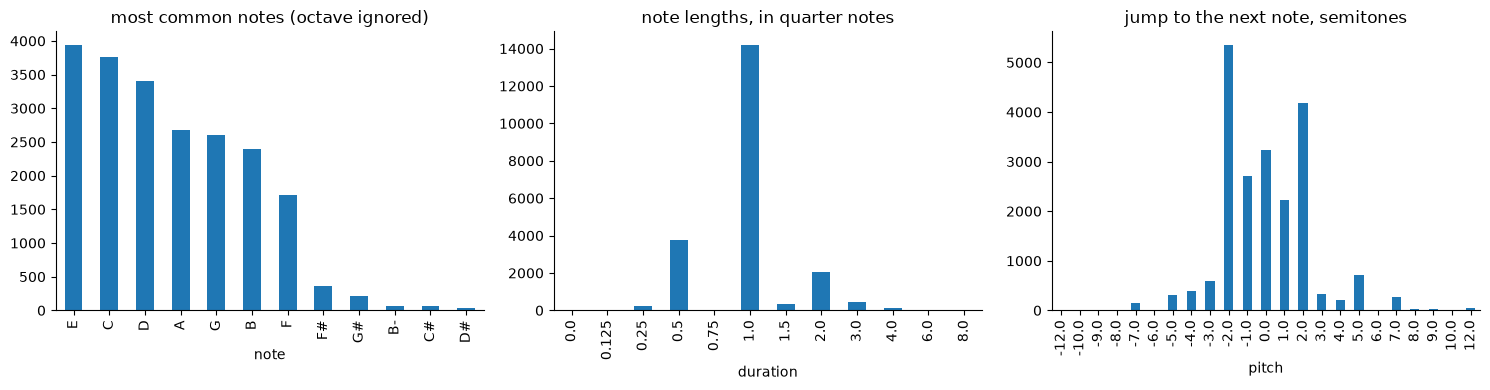

jumps of at most 2 semitones (a step up or down the scale, or a repeat): 85%


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
melodies.note.str[:-1].value_counts().head(12).plot.bar(ax=axes[0], title="most common notes (octave ignored)")
melodies.duration.value_counts().sort_index().plot.bar(ax=axes[1], title="note lengths, in quarter notes")
steps = melodies.groupby("chorale").pitch.diff().dropna()
steps.clip(-12, 12).value_counts().sort_index().plot.bar(ax=axes[2], title="jump to the next note, semitones")
plt.tight_layout()
plt.show()
print(f"jumps of at most 2 semitones (a step up or down the scale, or a repeat): {(steps.abs() <= 2).mean():.0%}")

The melodies move mostly by small steps, and most notes are quarter notes: hymns meant to be sung by a congregation.

## 2. The model

Each note is a pair: a pitch and a length. The network reads the last 16 notes and outputs two probability distributions, one for the next pitch and one for the next length. The chorales are split 80% / 20%, so the test melodies are ones the model never saw.

In [4]:
pitches = sorted(melodies.pitch.unique())
durations = sorted(melodies.duration.unique())
p_index = {p: i for i, p in enumerate(pitches)}
d_index = {d: i for i, d in enumerate(durations)}
melodies["p"] = melodies.pitch.map(p_index)
melodies["d"] = melodies.duration.map(d_index)

chorales = melodies.chorale.unique()
rng = np.random.default_rng(0)
test_chorales = set(rng.choice(chorales, size=len(chorales) // 5, replace=False))
WINDOW = 16

def windows(names):
    X_p, X_d, y_p, y_d = [], [], [], []
    for name in names:
        m = melodies[melodies.chorale == name]
        p, d = m.p.values, m.d.values
        for i in range(WINDOW, len(m)):
            X_p.append(p[i - WINDOW:i]); X_d.append(d[i - WINDOW:i]); y_p.append(p[i]); y_d.append(d[i])
    return [np.array(X_p), np.array(X_d)], [np.array(y_p), np.array(y_d)]

X_train, y_train = windows([c for c in chorales if c not in test_chorales])
X_test, y_test = windows(sorted(test_chorales))
print(f"training examples: {len(y_train[0]):,}, test examples: {len(y_test[0]):,}; "
      f"{len(pitches)} possible pitches, {len(durations)} possible lengths")

training examples: 11,897, test examples: 2,773; 35 possible pitches, 12 possible lengths


In [5]:
pitch_in = layers.Input(shape=(WINDOW,), name="pitches")
length_in = layers.Input(shape=(WINDOW,), name="lengths")
x = layers.Concatenate()([layers.Embedding(len(pitches), 32)(pitch_in), layers.Embedding(len(durations), 8)(length_in)])
x = layers.LSTM(128)(x)
x = layers.Dropout(0.3)(x)
pitch_out = layers.Dense(len(pitches), activation="softmax", name="next_pitch")(x)
length_out = layers.Dense(len(durations), activation="softmax", name="next_length")(x)
model = models.Model([pitch_in, length_in], [pitch_out, length_out])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
              metrics={"next_pitch": "accuracy", "next_length": "accuracy"})
history = model.fit(X_train, y_train, validation_split=0.1, epochs=40, batch_size=64, verbose=0,
                    callbacks=[tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)])
print(f"trained for {len(history.history['loss'])} epochs")

trained for 36 epochs


## 3. Does it beat simple rules?

Two rules to compare with, both learned from the training chorales:
- **repeat:** the next note has the same pitch as the last one;
- **most common next:** after a given pitch, pick the pitch that most often followed it.

For lengths, the rule is the most common length after the current one.

In [6]:
pred_p, pred_d = model.predict(X_test, verbose=0)
last_p, last_d = X_test[0][:, -1], X_test[1][:, -1]

train_pairs = pd.DataFrame({"now": X_train[0][:, -1], "next": y_train[0]})
bigram_p = train_pairs.groupby("now")["next"].agg(lambda s: s.value_counts().idxmax())
length_pairs = pd.DataFrame({"now": X_train[1][:, -1], "next": y_train[1]})
bigram_d = length_pairs.groupby("now")["next"].agg(lambda s: s.value_counts().idxmax())

def top3(probs, truth):
    return np.mean([t in np.argsort(-p)[:3] for p, t in zip(probs, truth)])

results = pd.DataFrame({
    "pitch right": [np.mean(last_p == y_test[0]), np.mean(bigram_p.reindex(last_p).values == y_test[0]), np.mean(pred_p.argmax(1) == y_test[0])],
    "pitch in top 3": [np.nan, np.nan, top3(pred_p, y_test[0])],
    "length right": [np.mean(last_d == y_test[1]), np.mean(bigram_d.reindex(last_d).values == y_test[1]), np.mean(pred_d.argmax(1) == y_test[1])],
}, index=["repeat", "most common next", "LSTM"])
results.round(3)

,pitch right,pitch in top 3,length right
repeat,0.140,NaN,0.641
most common next,0.440,NaN,0.711
LSTM,0.616,0.867,0.775


## 4. Writing a new melody

The network starts from the opening 16 notes of a test chorale and continues on its own, one note at a time. Instead of always taking the most likely note, it samples from its predicted probabilities (with a temperature below 1, which favors likely notes), so the melody doesn't get stuck repeating itself.

In [7]:
def generate(seed_p, seed_d, n=48, temperature=0.8):
    p, d = list(seed_p), list(seed_d)
    sample_rng = np.random.default_rng(3)
    for _ in range(n):
        probs_p, probs_d = model.predict([np.array([p[-WINDOW:]]), np.array([d[-WINDOW:]])], verbose=0)
        for probs, out in [(probs_p[0], p), (probs_d[0], d)]:
            logits = np.log(probs + 1e-9) / temperature
            weights = np.exp(logits - logits.max())
            out.append(sample_rng.choice(len(weights), p=weights / weights.sum()))
    return p, d

seed_name = sorted(test_chorales)[0]
seed = melodies[melodies.chorale == seed_name].head(WINDOW)
gen_p, gen_d = generate(seed.p.values, seed.d.values)

melody = stream.Stream([tempo.MetronomeMark(number=80)])
for i, (pi, di) in enumerate(zip(gen_p, gen_d)):
    melody.append(note.Note(pitches[pi], quarterLength=durations[di]))
melody.write("midi", fp="generated_melody.mid")
print(f"seed: the opening of {seed_name}; wrote {len(gen_p)} notes to generated_melody.mid")

seed: the opening of bwv1.6; wrote 64 notes to generated_melody.mid


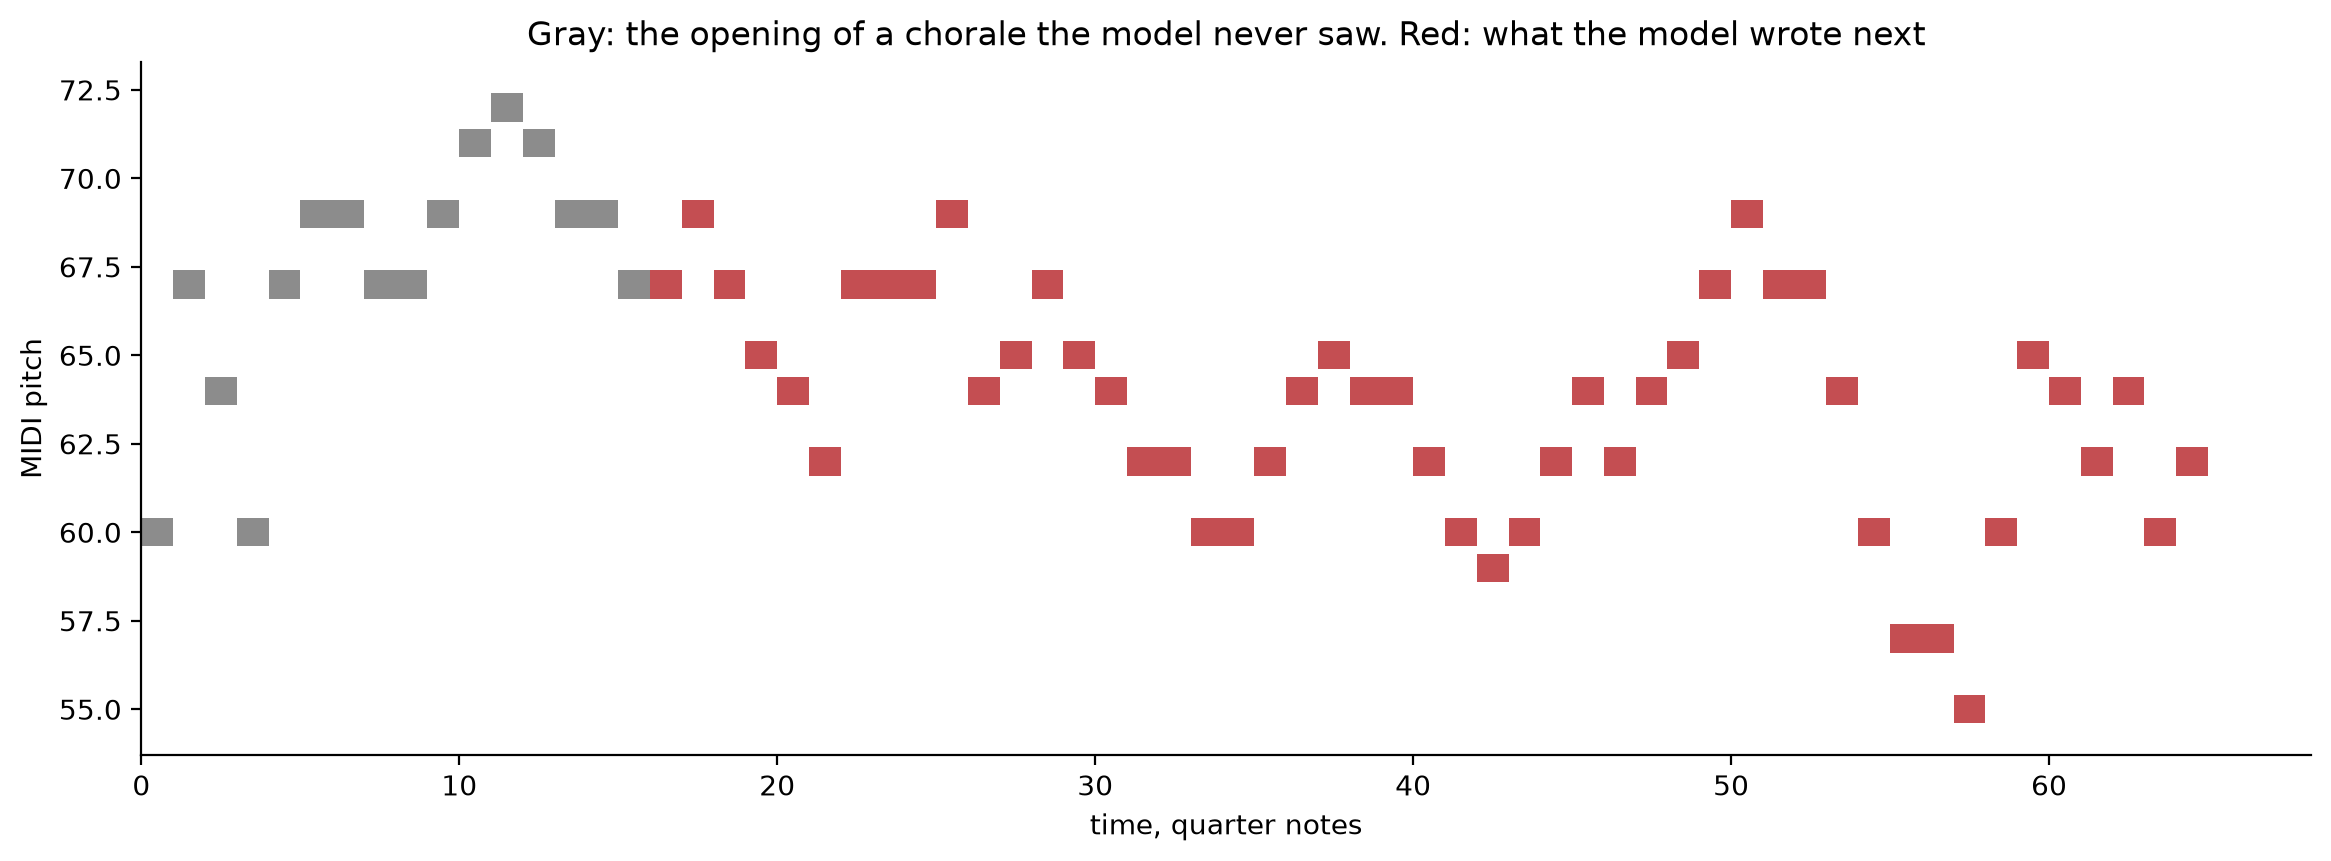

in the generated part, jumps of at most 2 semitones: 83% (in Bach's melodies: 85%)


In [8]:
def piano_roll(ax, p_idx, d_idx, start_color, split):
    t = 0.0
    for i, (pi, di) in enumerate(zip(p_idx, d_idx)):
        ax.barh(pitches[pi], durations[di], left=t, height=0.8, color=start_color if i < split else "#c44e52")
        t += durations[di]

fig, ax = plt.subplots(figsize=(14, 4.5))
piano_roll(ax, gen_p, gen_d, "#8c8c8c", WINDOW)
ax.set_xlabel("time, quarter notes")
ax.set_ylabel("MIDI pitch")
ax.set_title("Gray: the opening of a chorale the model never saw. Red: what the model wrote next")
plt.show()

generated = np.array(gen_p[WINDOW:])
jumps = np.abs(np.diff([pitches[i] for i in generated]))
print(f"in the generated part, jumps of at most 2 semitones: {(jumps <= 2).mean():.0%} (in Bach's melodies: {(steps.abs() <= 2).mean():.0%})")

## Results

- Bach's chorale melodies move mostly by small steps: 85% of the moves are a repeat or a step of at most 2 semitones, and most notes are quarter notes.
- On chorales it never saw, the LSTM names the next pitch correctly 62% of the time, and the right pitch is among its top 3 guesses 87% of the time. The best simple rule, the most common next pitch, gets 44%; repeating the last pitch gets 14%.
- It predicts the next note's length correctly 78% of the time, against 71% for the most common next length.
- Its own melody keeps the chorale style in the small: 83% of its moves are small steps, close to Bach's 85%. What it doesn't learn from 16 notes of context is the larger shape of a phrase, such as where a cadence comes; that would take a longer memory or a model that also knows the harmony.
- The generated melody is saved as [generated_melody.mid](generated_melody.mid), which plays in any MIDI player.

## Tools

Python, TensorFlow / Keras (LSTM), music21, pandas, NumPy, matplotlib